In [3]:
import pandas as pd
import matplotlib.pyplot as plt

1. Escribir un programa que pregunte al usuario por las ventas de un rango de años y muestre por pantalla un diagrama de líneas con la evolución de las ventas.


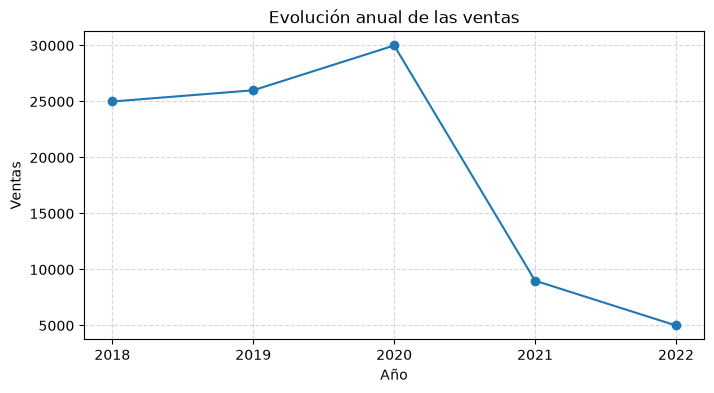

In [4]:
inicio = int(input("Introduce el año inicial: "))
fin = int(input("Introduce el año final: "))

ventas = {}
for anio in range(inicio, fin + 1):
    ventas[anio] = float(input(f"Introduce las ventas del año {anio}: "))

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(list(ventas.keys()), list(ventas.values()), marker="o", linestyle="-", color="tab:blue")

# Personalización 
ax.set_title("Evolución anual de las ventas")
ax.set_xlabel("Año")
ax.set_ylabel("Ventas")

ax.set_xticks(list(ventas.keys()))
ax.grid(True, linestyle="--", alpha=0.5)

plt.show()

2. Escribir una función que reciba una diccionario con las notas de las asignaturas de un curso y una cadena con el nombre de un color y devuelva un diagrama de barras de las notas en el color dado.

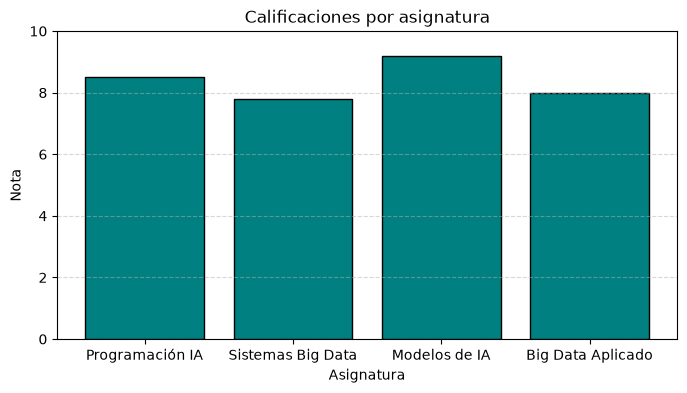

In [5]:
def graficar_notas_asignaturas(notas: dict, color: str):
    """Recibe un diccionario {asignatura: nota} y un color, y devuelve el eje con el gráfico de barras."""
    fig, ax = plt.subplots(figsize=(8, 4))
    
    # Extraemos claves (asignaturas) y valores (calificaciones) para generar las barras
    ax.bar(notas.keys(), notas.values(), color=color, edgecolor="black")
    
    ax.set_title("Calificaciones por asignatura")
    ax.set_xlabel("Asignatura")
    ax.set_ylabel("Nota")
    # Limitamos el eje Y de 0 a 10 para mantener la escala académica estándar
    ax.set_ylim(0, 10)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    
    return ax

notas_curso = {
    "Programación IA": 8.5,
    "Sistemas Big Data": 7.8,
    "Modelos de IA": 9.2,
    "Big Data Aplicado": 8.0
}
graficar_notas_asignaturas(notas_curso, color="teal")
plt.show()

3. Escribir una función que reciba una serie de Pandas con las notas de los alumnos de un curso y devuelva un diagrama de cajas con las notas. El diagrama debe tener el título “Distribución de notas”.

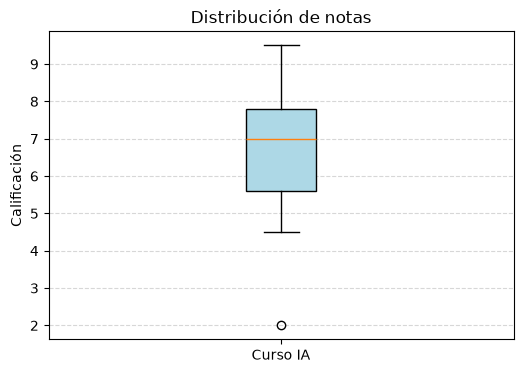

In [6]:
def graficar_caja_notas(serie_notas: pd.Series):
    """Recibe una Serie de Pandas con calificaciones y devuelve un diagrama de cajas."""
    fig, ax = plt.subplots(figsize=(6, 4))
    
    # Eliminamos posibles valores nulos
    datos_limpios = serie_notas.dropna()
    
    ax.boxplot(datos_limpios, patch_artist=True, boxprops=dict(facecolor="lightblue"))
    
    # Título
    ax.set_title("Distribución de notas")
    ax.set_ylabel("Calificación")
    ax.set_xticks([1])
    ax.set_xticklabels([serie_notas.name if serie_notas.name else "Alumnos"])
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    
    return ax

notas_alumnos = pd.Series([4.5, 5.0, 6.2, 6.8, 7.0, 7.4, 7.5, 8.1, 8.9, 9.5, 2.0], name="Curso IA")
graficar_caja_notas(notas_alumnos)
plt.show()

4. El fichero bancos.csv contiene las cotizaciones de los principales bancos de España con : Empresa (nombre de la empresa), Apertura (precio de la acción a la apertura de bolsa), Máximo (precio máximo de la acción durante la jornada), Mínimo (precio mínimo de la acción durante la jornada), Cierre (precio de la acción al cierre de bolsa), Volumen (volumen al cierre de bolsa). Construir una función reciba el fichero bancos.csv y cree un diagrama de líneas con las series temporales de las cotizaciones de cierre de cada banco.

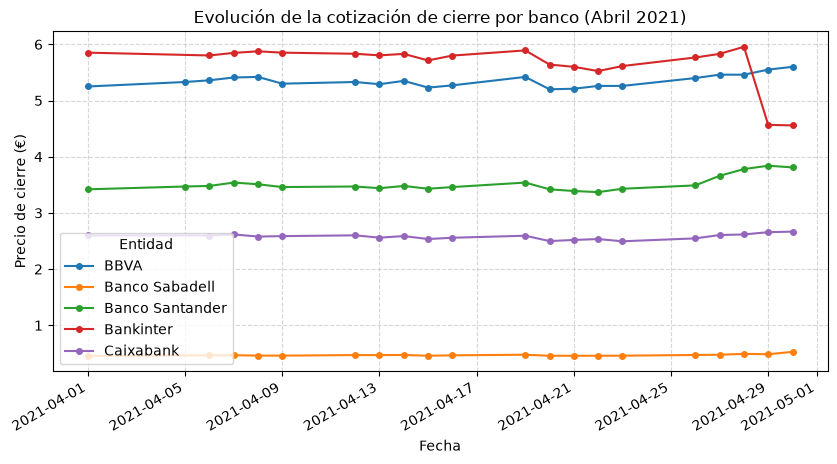

In [ ]:
def graficar_cierres_bancos(ruta_csv: str):
    """Lee el CSV de cotizaciones bancarias y grafica la serie temporal de cierre por banco."""
    df = pd.read_csv(ruta_csv)
    
    df["Fecha"] = pd.to_datetime(df["Fecha"])
    df = df.sort_values("Fecha")
    
    fig, ax = plt.subplots(figsize=(10, 5))
    
    for empresa, datos_banco in df.groupby("Empresa"):
        ax.plot(datos_banco["Fecha"], datos_banco["Cierre"], marker="o", markersize=4, label=empresa)
        
    ax.set_title("Evolución de la cotización de cierre por banco (Abril 2021)")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Precio de cierre (€)")
    ax.legend(title="Entidad")
    ax.grid(True, linestyle="--", alpha=0.5)
    
    fig.autofmt_xdate()
    
    return ax

graficar_cierres_bancos("bancos.csv")
plt.show()

5. El fichero titanic.csv contiene información sobre los pasajeros del Titanic. Crear un dataframe con Pandas y a partir de él generar los siguientes diagramas.

In [8]:
df_titanic = pd.read_csv("titanic.csv")


<small>Diagrama de sectores con los fallecidos y supervivientes.</small>

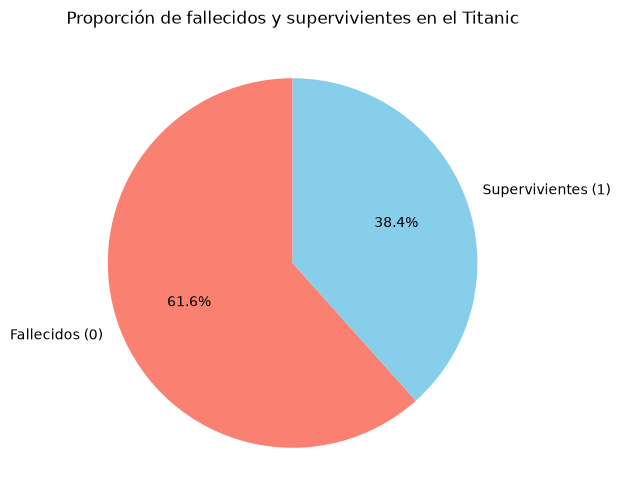

In [11]:
# Contamos frecuencias de la variable binaria Survived (0 = Fallecido, 1 = Superviviente)
conteo_supervivencia = df_titanic["Survived"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    conteo_supervivencia,
    labels=["Fallecidos (0)", "Supervivientes (1)"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["salmon", "skyblue"]
)
ax.set_title("Proporción de fallecidos y supervivientes en el Titanic")
plt.show()

<small>Histograma con las edades.</small>

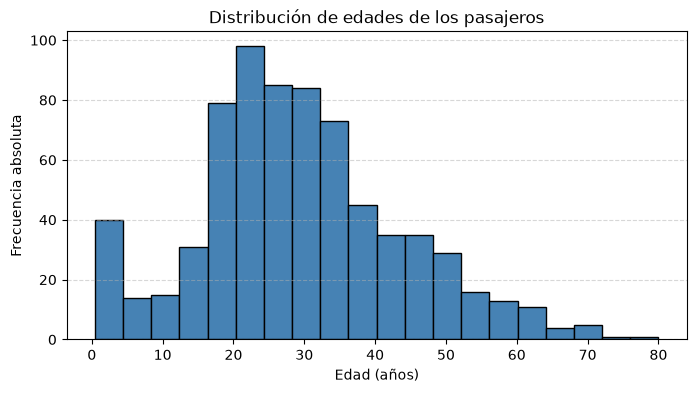

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))

# Filtramos los 177 registros sin edad (NaN) antes de calcular los intervalos (bins)
ax.hist(df_titanic["Age"].dropna(), bins=20, color="steelblue", edgecolor="black")

ax.set_title("Distribución de edades de los pasajeros")
ax.set_xlabel("Edad (años)")
ax.set_ylabel("Frecuencia absoluta")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

<small>Diagrama de barras con el número de personas en cada clase.</small>

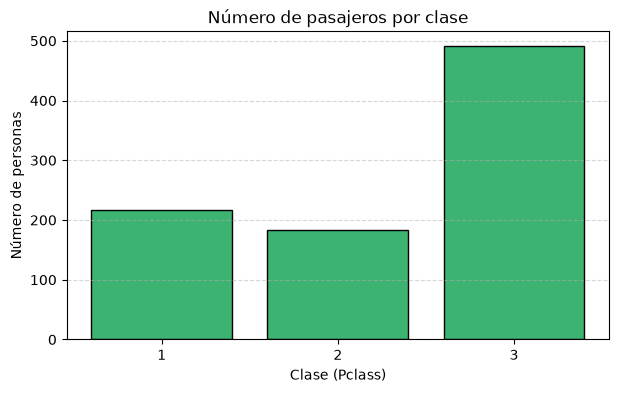

In [13]:
# Ordenamos el índice para mostrar 1ª, 2ª y 3ª clase en orden ascendente
conteo_clases = df_titanic["Pclass"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(conteo_clases.index.astype(str), conteo_clases.values, color="mediumseagreen", edgecolor="black")

ax.set_title("Número de pasajeros por clase")
ax.set_xlabel("Clase (Pclass)")
ax.set_ylabel("Número de personas")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

<small>Diagrama de barras con el número de personas fallecidas y supervivientes en cada clase.</small>

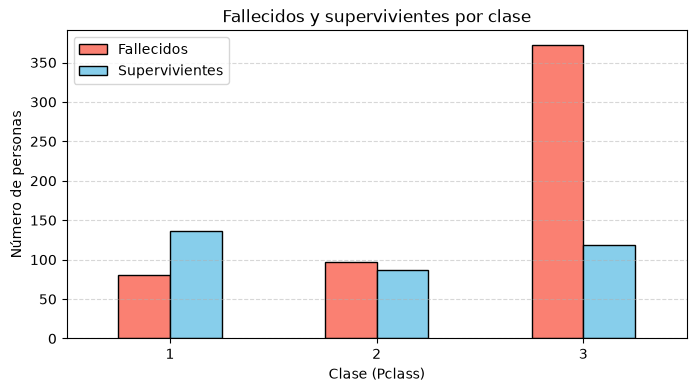

In [14]:
# Tabla de contingencia cruzando Clase (filas) y Supervivencia (columnas)
tabla_clase_sup = pd.crosstab(df_titanic["Pclass"], df_titanic["Survived"])
tabla_clase_sup.columns = ["Fallecidos", "Supervivientes"]

ax = tabla_clase_sup.plot(kind="bar", stacked=False, figsize=(8, 4), color=["salmon", "skyblue"], edgecolor="black")
ax.set_title("Fallecidos y supervivientes por clase")
ax.set_xlabel("Clase (Pclass)")
ax.set_ylabel("Número de personas")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

<small>Diagrama de barras con el número de personas fallecidas y supervivientes acumuladas en cada clase.</small>

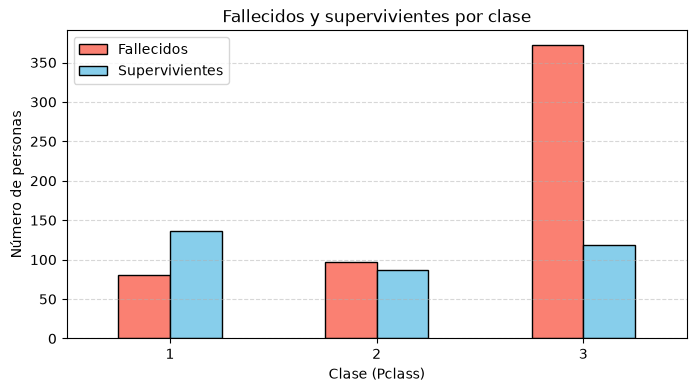

In [15]:
# Tabla de contingencia cruzando Clase (filas) y Supervivencia (columnas)
tabla_clase_sup = pd.crosstab(df_titanic["Pclass"], df_titanic["Survived"])
tabla_clase_sup.columns = ["Fallecidos", "Supervivientes"]

ax = tabla_clase_sup.plot(kind="bar", stacked=False, figsize=(8, 4), color=["salmon", "skyblue"], edgecolor="black")
ax.set_title("Fallecidos y supervivientes por clase")
ax.set_xlabel("Clase (Pclass)")
ax.set_ylabel("Número de personas")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

<small>Diagrama de barras con el número de personas fallecidas y supervivientes acumuladas en cada clase.</small>

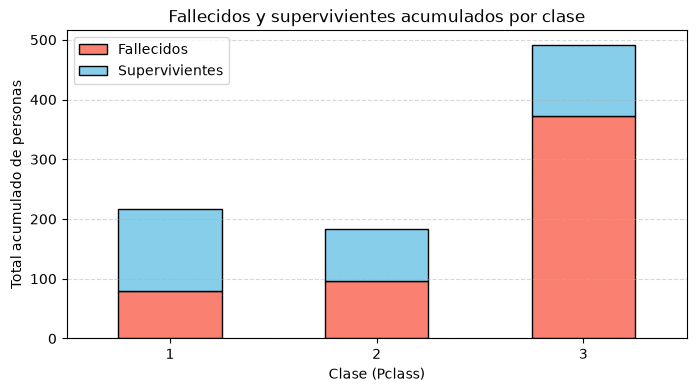

In [16]:
# Reutilizamos la tabla de contingencia activando el apilamiento vertical (stacked=True)
ax = tabla_clase_sup.plot(kind="bar", stacked=True, figsize=(8, 4), color=["salmon", "skyblue"], edgecolor="black")
ax.set_title("Fallecidos y supervivientes acumulados por clase")
ax.set_xlabel("Clase (Pclass)")
ax.set_ylabel("Total acumulado de personas")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [17]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Cargar el conjunto de datos 'tips' de Seaborn
df = sns.load_dataset('tips')

6 Usando el dataset tips de Seaborn, crea una figura con 2 filas y 3 columnas en la que sitúes las siguientes gráficas:

* Un gráfico de barras que muestre el total de la cuenta (total_bill) por día (day).
* Un gráfico de líneas que muestre la relación entre el total de la cuenta (total_bill) y la propina (tip). Muestra también con una línea la propina media.
* Un gráfico de dispersión entre el total de la cuenta (total_bill) y la propina (tip).
* Un gráfico circular que muestre la distribución del total de la cuenta por sexo (sex).
* Un histograma para la distribución del total de la cuenta (total_bill).
* Un gráfico de caja y bigotes con los valores de las propinas (tip) en función del día de la semana (day).


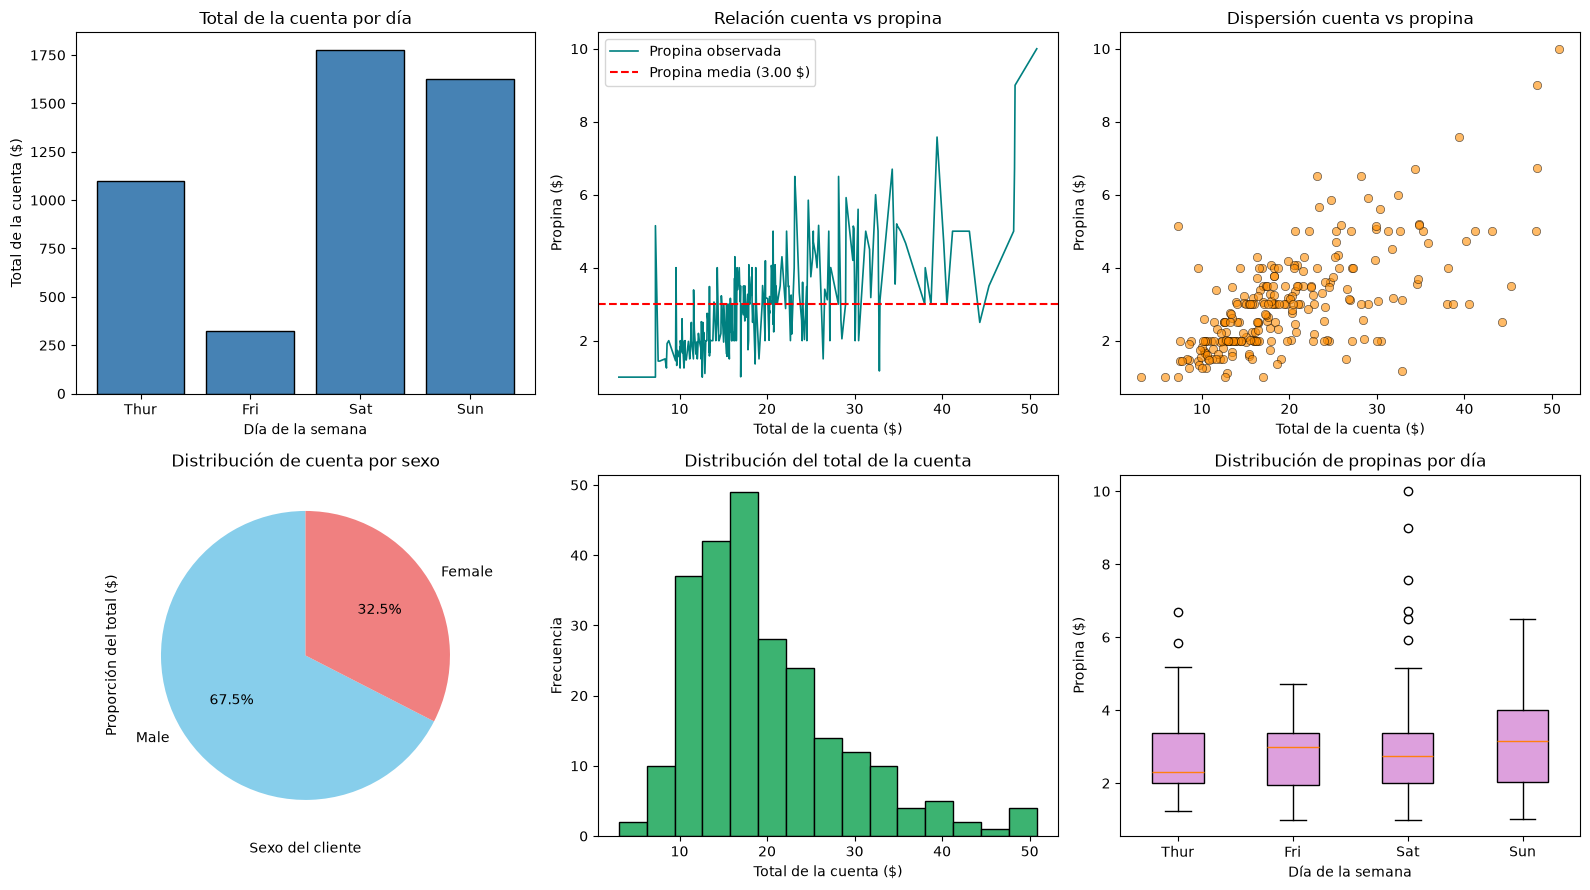

In [25]:
# Creamos la figura con una cuadrícula de 2 filas y 3 columnas
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# 1. [0, 0] Gráfico de barras: total de la cuenta por día
cuenta_por_dia = df.groupby('day', observed=False)['total_bill'].sum()
axes[0, 0].bar(cuenta_por_dia.index, cuenta_por_dia.values, color='steelblue', edgecolor='black')
axes[0, 0].set_title('Total de la cuenta por día')
axes[0, 0].set_xlabel('Día de la semana')
axes[0, 0].set_ylabel('Total de la cuenta ($)')

# 2. [0, 1] Gráfico de líneas: relación entre total_bill y tip + línea de propina media
df_ordenado = df.sort_values('total_bill')
media_propina = df['tip'].mean()
axes[0, 1].plot(df_ordenado['total_bill'], df_ordenado['tip'], color='teal', linewidth=1.2, label='Propina observada')
axes[0, 1].axhline(media_propina, color='red', linestyle='--', linewidth=1.5, label=f'Propina media ({media_propina:.2f} $)')
axes[0, 1].set_title('Relación cuenta vs propina')
axes[0, 1].set_xlabel('Total de la cuenta ($)')
axes[0, 1].set_ylabel('Propina ($)')
axes[0, 1].legend()

# 3. [0, 2] Gráfico de dispersión: total_bill vs tip
axes[0, 2].scatter(df['total_bill'], df['tip'], alpha=0.6, color='darkorange', edgecolors='black', linewidth=0.5)
axes[0, 2].set_title('Dispersión cuenta vs propina')
axes[0, 2].set_xlabel('Total de la cuenta ($)')
axes[0, 2].set_ylabel('Propina ($)')

# 4. [1, 0] Gráfico circular: distribución del total de la cuenta por sexo
cuenta_por_sexo = df.groupby('sex', observed=False)['total_bill'].sum()
axes[1, 0].pie(
    cuenta_por_sexo.values,
    labels=cuenta_por_sexo.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['skyblue', 'lightcoral']
)
axes[1, 0].set_title('Distribución de cuenta por sexo')
axes[1, 0].set_xlabel('Sexo del cliente')
axes[1, 0].set_ylabel('Proporción del total ($)')

# 5. [1, 1] Histograma: distribución de total_bill
axes[1, 1].hist(df['total_bill'], bins=15, color='mediumseagreen', edgecolor='black')
axes[1, 1].set_title('Distribución del total de la cuenta')
axes[1, 1].set_xlabel('Total de la cuenta ($)')
axes[1, 1].set_ylabel('Frecuencia')

# 6. [1, 2] Diagrama de caja y bigotes: propinas por día de la semana
categorias_dias = df['day'].cat.categories
propinas_por_dia = [df[df['day'] == dia]['tip'] for dia in categorias_dias]
axes[1, 2].boxplot(propinas_por_dia, patch_artist=True, boxprops=dict(facecolor='plum'))
axes[1, 2].set_xticklabels(categorias_dias)
axes[1, 2].set_title('Distribución de propinas por día')
axes[1, 2].set_xlabel('Día de la semana')
axes[1, 2].set_ylabel('Propina ($)')

plt.tight_layout()
plt.show()

7. Usando el dataset tips de Seaborn, crea un gráfico de barras apiladas para mostrar cómo se distribuyen las propinas por día y por sexo.
Personaliza el gráfico añadiendo un título, etiquetas a los ejes y ajustando los colores de las barras.


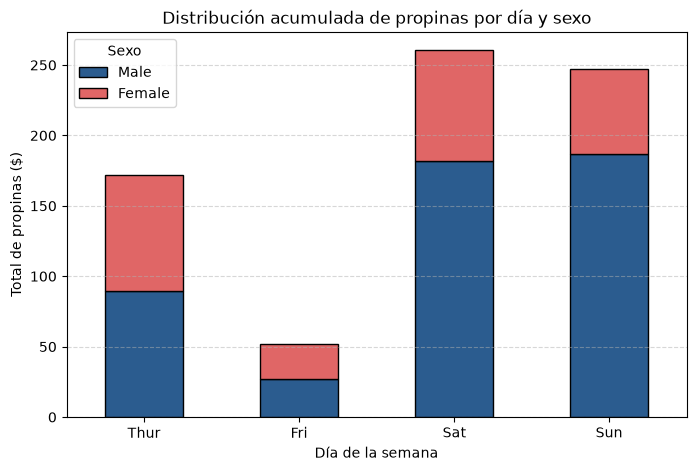

In [ ]:
# Generamos una tabla bidimensional (filas=día, columnas=sexo) con la suma de propinas
propinas_dia_sexo = df.groupby(['day', 'sex'], observed=False)['tip'].sum().unstack()

# Trazamos las barras apiladas personalizando la paleta de colores
ax = propinas_dia_sexo.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    color=['#2b5c8f', '#e06666'],
    edgecolor='black'
)

ax.set_title('Distribución acumulada de propinas por día y sexo')
ax.set_xlabel('Día de la semana')
ax.set_ylabel('Total de propinas ($)')
ax.legend(title='Sexo')

ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

8. Usando el dataset tips de Seaborn, crea un gráfico de líneas en el que se representen dos series:
* La relación entre total_bill y tip.
* La relación entre total_bill y el tamaño de la mesa (size).

Añade una leyenda que identifique las dos series y personaliza el gráfico añadiendo un título y etiquetas a los ejes.


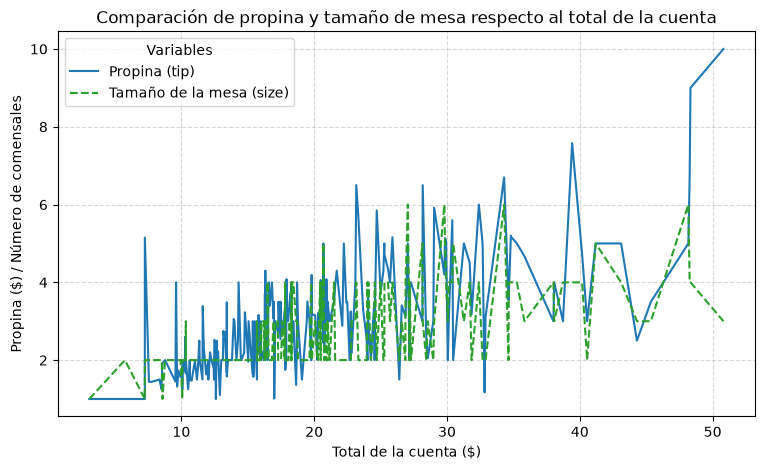

In [20]:
# Ordenamos por la variable independiente (total_bill) para trazar ambas series de forma continua
df_ordenado = df.sort_values('total_bill')

fig, ax = plt.subplots(figsize=(9, 5))

# Primera serie: relación entre total_bill y tip
ax.plot(df_ordenado['total_bill'], df_ordenado['tip'], color='tab:blue', label='Propina (tip)')

# Segunda serie: relación entre total_bill y size
ax.plot(df_ordenado['total_bill'], df_ordenado['size'], color='tab:green', linestyle='--', label='Tamaño de la mesa (size)')

ax.set_title('Comparación de propina y tamaño de mesa respecto al total de la cuenta')
ax.set_xlabel('Total de la cuenta ($)')
ax.set_ylabel('Propina ($) / Número de comensales')
ax.legend(title='Variables')
ax.grid(True, linestyle='--', alpha=0.5)

plt.show()

9. Usando el dataset tips de Seaborn, crea un gráfico de dispersión entre total_bill y tip. 

Asigna colores diferentes a los puntos del gráfico según el género (sex) del cliente, utilizando color='blue' para los hombres y color='red' para las mujeres. 

Personaliza el gráfico añadiendo un título, etiquetas a los ejes y una leyenda.

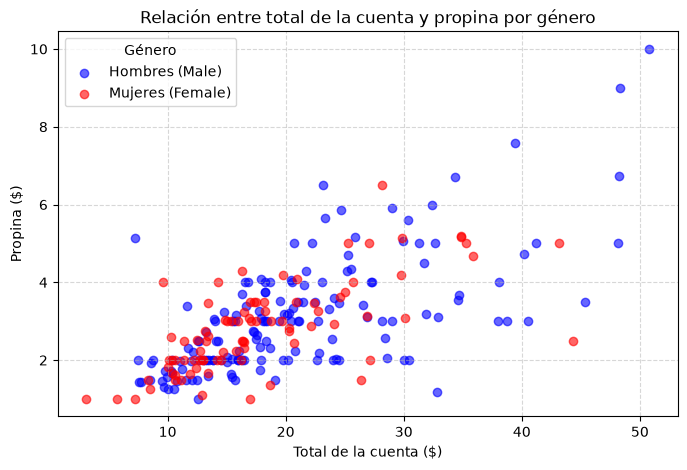

In [21]:
# Filtramos el DataFrame en dos subconjuntos
hombres = df[df['sex'] == 'Male']
mujeres = df[df['sex'] == 'Female']

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(hombres['total_bill'], hombres['tip'], color='blue', alpha=0.6, label='Hombres (Male)')
ax.scatter(mujeres['total_bill'], mujeres['tip'], color='red', alpha=0.6, label='Mujeres (Female)')

ax.set_title('Relación entre total de la cuenta y propina por género')
ax.set_xlabel('Total de la cuenta ($)')
ax.set_ylabel('Propina ($)')
ax.legend(title='Género')
ax.grid(True, linestyle='--', alpha=0.5)

plt.show()

10. Usando el dataset tips de Seaborn, crea una figura con subgráficos que contengan diferentes tipos de gráficos.

En el primer subgráfico, crea un gráfico de barras que muestre la relación entre day y total_bill.

En el segundo subgráfico, crea un gráfico circular que muestre la distribución de total_bill entre los géneros (sex).

Personaliza ambos gráficos con títulos, etiquetas en los ejes y ajuste del espacio entre los gráficos.


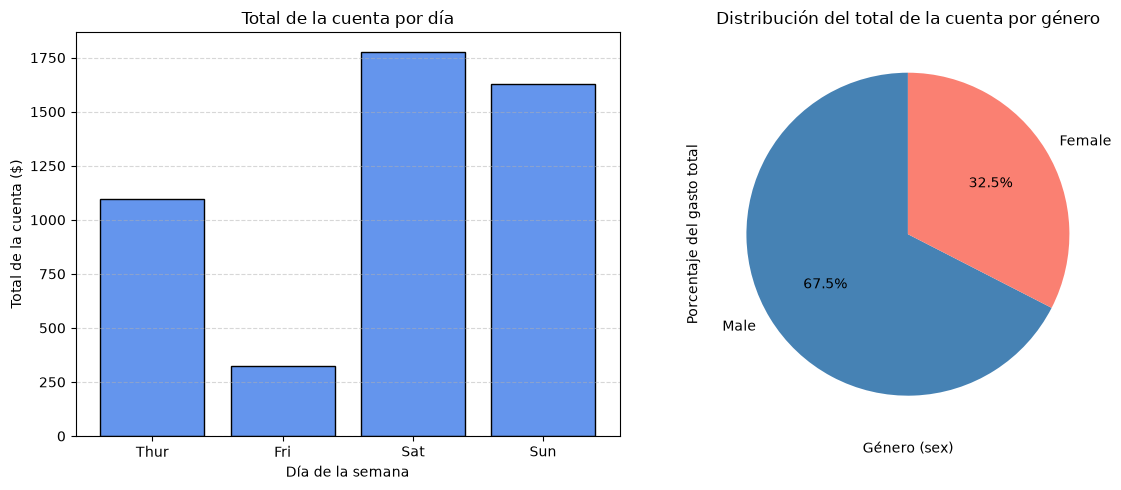

In [22]:
# Creamos una figura con 1 fila y 2 columnas para combinar dos geometrías distintas
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Primer subgráfico: diagrama de barras entre day y total_bill
cuenta_dia = df.groupby('day', observed=False)['total_bill'].sum()
axes[0].bar(cuenta_dia.index, cuenta_dia.values, color='cornflowerblue', edgecolor='black')
axes[0].set_title('Total de la cuenta por día')
axes[0].set_xlabel('Día de la semana')
axes[0].set_ylabel('Total de la cuenta ($)')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Segundo subgráfico: diagrama circular de total_bill entre géneros (sex)
cuenta_sexo = df.groupby('sex', observed=False)['total_bill'].sum()
axes[1].pie(
    cuenta_sexo.values,
    labels=cuenta_sexo.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['steelblue', 'salmon']
)
axes[1].set_title('Distribución del total de la cuenta por género')
axes[1].set_xlabel('Género (sex)')
axes[1].set_ylabel('Porcentaje del gasto total')

# Ajustamos el espaciado horizontal entre ambos subgráficos
plt.tight_layout()
plt.show()

11. Usando el dataset tips de Seaborn, crea un gráfico de de dispersión que muestre la relación entre total_bill y tip.

Ajusta una línea de tendencia (regresión lineal) a los datos utilizando scipy.stats.linregress().

Muestra la línea de tendencia en el gráfico junto con los puntos de dispersión.

Personaliza el gráfico con un título, etiquetas a los ejes y una leyenda que indique la línea de tendencia.


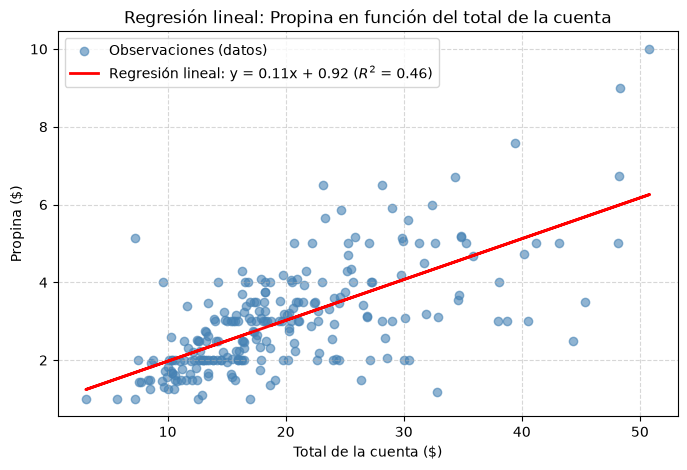

In [ ]:
# Calculamos los parámetros de la regresión lineal por mínimos cuadrados ordinarios
resultado = linregress(df['total_bill'], df['tip'])
pendiente = resultado.slope
intercepto = resultado.intercept
r_cuadrado = resultado.rvalue ** 2

# Calculamos los valores predichos (y_hat = m*x + b) sobre el rango de total_bill
x_valores = df['total_bill']
y_tendencia = intercepto + pendiente * x_valores

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df['total_bill'], df['tip'], color='steelblue', alpha=0.6, label='Observaciones (datos)')

# Línea de tendencia
ax.plot(
    x_valores,
    y_tendencia,
    color='red',
    linewidth=2,
    label=f'Regresión lineal: y = {pendiente:.2f}x + {intercepto:.2f} ($R^2$ = {r_cuadrado:.2f})'
)

ax.set_title('Regresión lineal: Propina en función del total de la cuenta')
ax.set_xlabel('Total de la cuenta ($)')
ax.set_ylabel('Propina ($)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

plt.show()